# Late deliveries: analysis

This notebook reads the work done by `python -m latedeliveries.train` and shows it.
Everything the model learns from comes from the training set. The test set is scored once, inside `train.py`, and the notebook only reads that result from `reports/metrics.json`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from latedeliveries.data import make_orders
from latedeliveries.evaluation import cost_curve, order_cost
from latedeliveries.pipeline import (
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    split_orders,
)
from latedeliveries.train import (
    make_folds,
    out_of_fold_probabilities,
    tune_logistic,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
info = json.loads((ROOT / "models" / "model_info.json").read_text())

## 1. How common are late orders, and what is missing?

In [2]:
orders = make_orders()
x_train, x_test, y_train, y_test = split_orders(orders)
print(f"Orders: {len(orders)}   late rate: {orders['late'].mean():.3f}")
print(f"Train: {len(x_train)} orders, late rate {y_train.mean():.3f}")
print(f"Test:  {len(x_test)} orders, late rate {y_test.mean():.3f}")
orders.isna().mean().round(3).loc[lambda s: s > 0].rename("share missing")

Orders: 3000   late rate: 0.156
Train: 2250 orders, late rate 0.156
Test:  750 orders, late rate 0.156


prep_minutes       0.063
customer_rating    0.496
Name: share missing, dtype: float64

About one order in six is late (0.156), so a model that never flags anything is right 84 percent of the time and finds no late order at all. `prep_minutes` and `customer_rating` have gaps, and both are left out of the model anyway, for the reasons in the README.

## 2. Model comparison (cross-validation on the training set)

In [3]:
cv = pd.read_csv(ROOT / "reports" / "cv_results.csv")
table = pd.DataFrame({"model": cv["model"]})
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    table[metric] = [
        f"{m:.3f} ± {s:.3f}"
        for m, s in zip(cv[f"{metric}_mean"], cv[f"{metric}_std"], strict=True)
    ]
table

,model,accuracy,precision,recall,f1,roc_auc
0,dummy_most_frequent,0.844 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
1,logistic,0.862 ± 0.013,0.669 ± 0.114,0.222 ± 0.066,0.330 ± 0.086,0.779 ± 0.038
2,logistic_balanced,0.731 ± 0.026,0.323 ± 0.035,0.655 ± 0.054,0.432 ± 0.040,0.779 ± 0.038
3,random_forest,0.850 ± 0.009,0.541 ± 0.073,0.213 ± 0.055,0.305 ± 0.067,0.736 ± 0.030
4,random_forest_balanced,0.823 ± 0.009,0.426 ± 0.033,0.387 ± 0.054,0.405 ± 0.040,0.739 ± 0.021
5,hist_gradient_boosting,0.847 ± 0.009,0.525 ± 0.058,0.279 ± 0.026,0.362 ± 0.020,0.745 ± 0.012


The plain logistic model has the best accuracy and the balanced one has the best F1 and recall. Because a missed late order costs $15 and a voucher $4, finding late orders matters more than accuracy, so I kept the balanced logistic model and tuned it.

## 3. Cost against threshold (training data only)

Best settings: {'model__C': 0.01, 'model__class_weight': 'balanced'} | CV F1: 0.4464


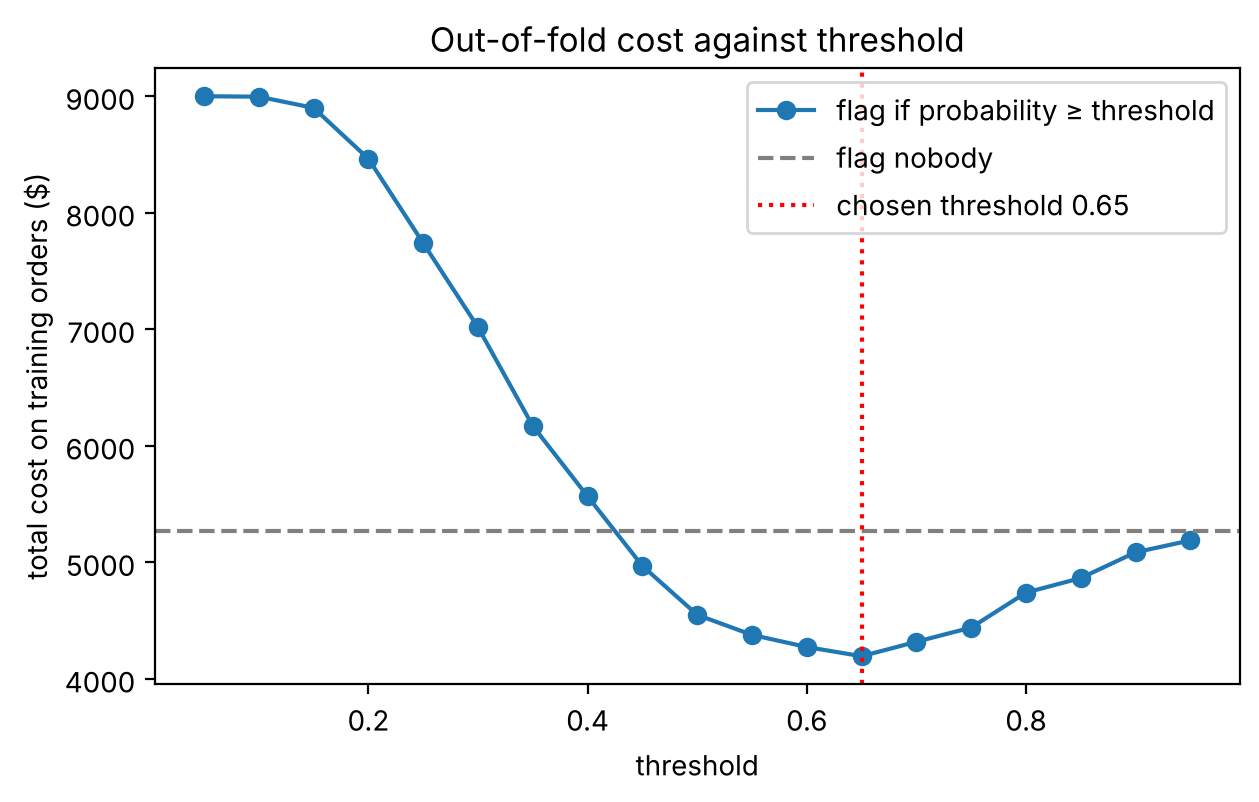

Cost at chosen threshold: 4194
Cost if nobody is flagged: 5265


In [4]:
search = tune_logistic(x_train, y_train)
best_pipe = search.best_estimator_
print("Best settings:", search.best_params_, "| CV F1:", round(search.best_score_, 4))

proba = out_of_fold_probabilities(best_pipe, x_train, y_train)
curve = pd.DataFrame(cost_curve(y_train, proba), columns=["threshold", "cost"])
chosen = info["threshold"]
nobody = order_cost(y_train, [False] * len(y_train))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    curve["threshold"],
    curve["cost"],
    marker="o",
    label="flag if probability ≥ threshold",
)
ax.axhline(nobody, color="grey", linestyle="--", label="flag nobody")
ax.axvline(chosen, color="red", linestyle=":", label=f"chosen threshold {chosen}")
ax.set_xlabel("threshold")
ax.set_ylabel("total cost on training orders ($)")
ax.set_title("Out-of-fold cost against threshold")
ax.legend()
plt.show()
print(
    "Cost at chosen threshold:",
    int(curve.loc[curve.threshold == chosen, "cost"].iloc[0]),
)
print("Cost if nobody is flagged:", nobody)

The cheapest threshold is far above 0.5, because the balanced model pushes many probabilities up. The curve is shallow around its minimum, so I would not read much into the exact value.

## 4. Test set: confusion matrix and the cost of three policies

                  predicted on time  predicted late
actually on time                586              47
actually late                    73              44
{'threshold': 0.65, 'precision': 0.4835, 'recall': 0.3761, 'f1': 0.4231, 'roc_auc': 0.7747}


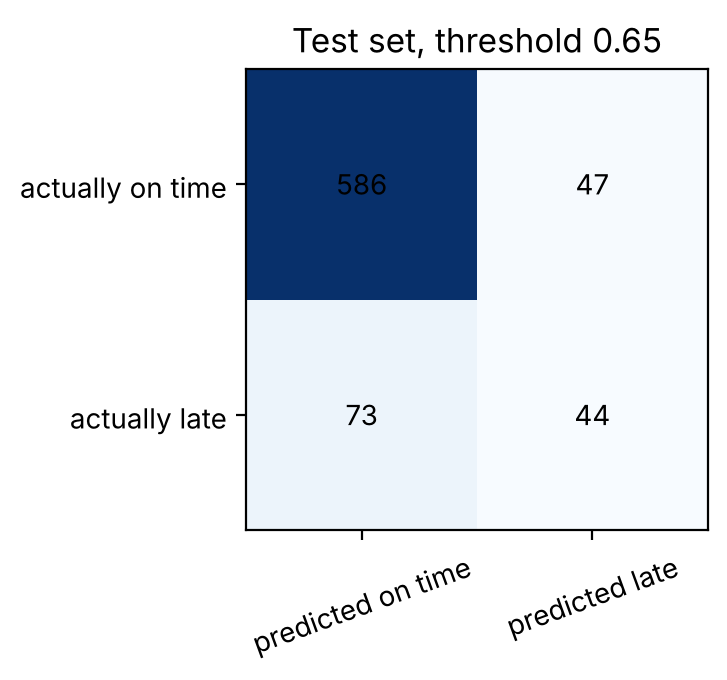

In [5]:
matrix = pd.DataFrame(
    metrics["confusion_matrix"],
    index=["actually on time", "actually late"],
    columns=["predicted on time", "predicted late"],
)
print(matrix)
print({k: metrics[k] for k in ["threshold", "precision", "recall", "f1", "roc_auc"]})

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(matrix.values, cmap="Blues")
ax.set_xticks([0, 1], matrix.columns, rotation=20)
ax.set_yticks([0, 1], matrix.index)
for i in range(2):
    for j in range(2):
        ax.text(j, i, matrix.values[i, j], ha="center", va="center")
ax.set_title("Test set, threshold " + str(metrics["threshold"]))
plt.tight_layout()
plt.show()

flag nobody       1755
flag everybody    3000
use the model     1459
Name: test cost ($), dtype: int64
Saving against flagging nobody: $296 (17%)


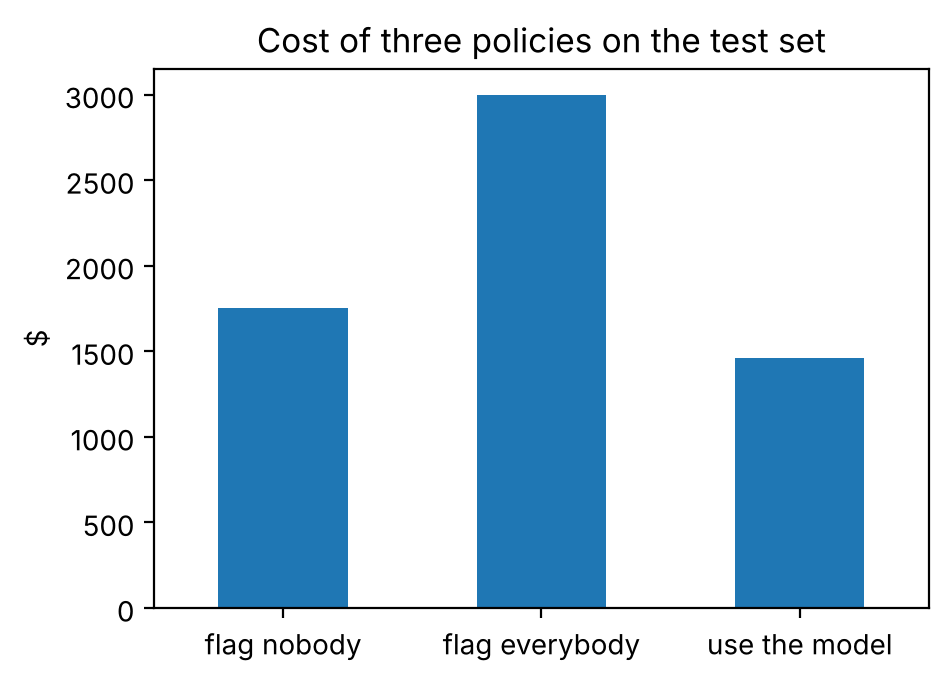

In [6]:
costs = pd.Series(
    {
        "flag nobody": metrics["cost_flag_nobody"],
        "flag everybody": metrics["cost_flag_everybody"],
        "use the model": metrics["cost_model"],
    },
    name="test cost ($)",
)
print(costs)
saving = costs["flag nobody"] - costs["use the model"]
print(
    f"Saving against flagging nobody: ${saving} ({saving / costs['flag nobody']:.0%})"
)
costs.plot.bar(rot=0, figsize=(5, 3.5), title="Cost of three policies on the test set")
plt.ylabel("$")
plt.show()

## 5. Leakage check

To see leakage for myself, I run the same cross-validation on the training set with `customer_rating` added back. This is not part of the model. It is only a demonstration.

In [7]:
rating_train = orders.loc[x_train.index, "customer_rating"]
x_with_rating = x_train.assign(customer_rating=rating_train)


def make_pipe(numeric):
    prep = ColumnTransformer(
        [
            (
                "num",
                make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                numeric,
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                CATEGORICAL_FEATURES,
            ),
        ]
    )
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])


without = cross_val_score(
    make_pipe(NUMERIC_FEATURES), x_train, y_train, cv=make_folds(), scoring="roc_auc"
)
with_rating = cross_val_score(
    make_pipe([*NUMERIC_FEATURES, "customer_rating"]),
    x_with_rating,
    y_train,
    cv=make_folds(),
    scoring="roc_auc",
)
print(f"ROC-AUC without customer_rating: {without.mean():.3f}")
print(f"ROC-AUC with customer_rating:    {with_rating.mean():.3f}")

ROC-AUC without customer_rating: 0.779
ROC-AUC with customer_rating:    0.905


The score jumps when the rating is added. A rating is only given after delivery and is made from whether the order was late, so that jump is leakage, not skill. The column stays out.

## Recommendation

I would use this model, but only as a way to decide who gets a voucher, not as a promise that an order will be late. On 750 test orders it cost $1,459 against $1,755 for flagging nobody and $3,000 for flagging everybody. That is a small but real saving.

I chose a threshold of 0.65 because the company's costs set it, not the usual 0.5. It was picked on out-of-fold training predictions, the cheapest of 19 candidates.

I left out `order_id` (a label), `prep_minutes` (only known after the kitchen finishes) and `customer_rating` (given after delivery, and it leaks the answer).

One limitation: the data are invented, and the test set holds only 117 late orders, so trust the direction of the saving more than the exact $296.